In [1]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

from idxlab.clean import clean_ticker_data
from idxlab.config import load_config
from idxlab.data import DataLoader
from idxlab.evaluation import (
    bootstrap_auc_ci,
    evaluate_classifier,
    paired_bootstrap_auc_diff,
)
from idxlab.logging_setup import setup_logging
from idxlab.split import build_dataset, time_based_split
from idxlab.backtest import proba_to_signal, run_backtest
from idxlab.metrics import exposure_matched_return, summarize
from idxlab.walkforward import walk_forward_proba

Path("docs/results").mkdir(parents=True, exist_ok=True)
Path("docs/figures").mkdir(parents=True, exist_ok=True)

cfg = load_config()
setup_logging(cfg.log_level)
loader = DataLoader.from_config(cfg)
raw = loader.load_all()

14:48:42 | INFO     | idxlab.data | Cache hit for BBCA.JK (data\raw\BBCA_JK.parquet)
14:48:42 | INFO     | idxlab.data | Cache hit for BBRI.JK (data\raw\BBRI_JK.parquet)
14:48:42 | INFO     | idxlab.data | Cache hit for TLKM.JK (data\raw\TLKM_JK.parquet)
14:48:42 | INFO     | idxlab.data | Cache hit for ASII.JK (data\raw\ASII_JK.parquet)
14:48:42 | INFO     | idxlab.data | Cache hit for UNVR.JK (data\raw\UNVR_JK.parquet)


In [ ]:
best = json.loads(Path("docs/results/day16_best_params.json").read_text(encoding="utf-8"))

# Order matters: simplest first. This is the challenge order in the protocol.
candidates = {
    "logreg": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "rf_default": RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42, n_jobs=-1
    ),
    "rf_tuned": RandomForestClassifier(**best["rf"]),
    "xgb_default": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=42, n_jobs=1,
    ),
    "xgb_tuned": XGBClassifier(**best["xgb"]),
}
dummy = DummyClassifier(strategy="most_frequent")  # reference only, not a candidate

chosen = "logreg"                 
model = candidates[chosen]

Walk-forward: train_size=250, step=20, gap=1, rolling. Hanya train+val; test tidak disentuh.

In [3]:
ohlcv = clean_ticker_data(raw["BBCA.JK"])
dataset = build_dataset(ohlcv)
split = time_based_split(dataset)
feature_cols = [c for c in dataset.columns if c not in ("forward_return", "direction")]

dev = pd.concat([split.train, split.val])      
returns = ohlcv["Close"].pct_change()
PARAMS = dict(train_size=250, step=20, gap=1, rolling=True)
print(len(dev), "baris dev;", len(split.val), "baris val;", len(split.test), "baris test (tidak dipakai)")

722 baris dev; 127 baris val; 128 baris test (tidak dipakai)


In [4]:
proba_wf = walk_forward_proba(dev, model, feature_cols, **PARAMS)     

# pengaman: tidak boleh ada prediksi di periode test
assert proba_wf.index.isin(split.test.index).sum() == 0
assert proba_wf.index.max() <= split.val.index.max()
print(len(proba_wf), "hari prediksi out-of-sample,", proba_wf.index.min().date(), "->", proba_wf.index.max().date())

471 hari prediksi out-of-sample, 2024-02-19 -> 2026-02-12


In [5]:
def describe(daily, rets, proba, y):
    s = summarize(daily)
    s["bench_matched"] = exposure_matched_return(rets, s["exposure"])
    s["auc"] = roc_auc_score(y, proba)                           
    s["n_days"] = float(len(daily))
    return s

# A. Statis (seperti Day 20): fit sekali di train, uji di val
fitted = clone(model).fit(split.train[feature_cols], split.train["direction"].astype(int))
proba_static = pd.Series(fitted.predict_proba(split.val[feature_cols])[:, 1], index=split.val.index)
r_val = returns.loc[split.val.index]
A = describe(run_backtest(r_val, proba_to_signal(proba_static)), r_val, proba_static, split.val["direction"])

# B. Walk-forward, hanya di tanggal val yang sama dengan A
p_val = proba_wf.loc[split.val.index]                               # [10] indeks tanggal val
r_p = returns.loc[p_val.index]
B = describe(run_backtest(r_p, proba_to_signal(p_val)), r_p, p_val, dev.loc[p_val.index, "direction"])

# C. Walk-forward, seluruh periode out-of-sample
r_wf = returns.loc[proba_wf.index]
daily_wf = run_backtest(r_wf, proba_to_signal(proba_wf))
C = describe(daily_wf, r_wf, proba_wf, dev.loc[proba_wf.index, "direction"])

table = pd.DataFrame({"A. Static, val": A, "B. Walk-forward, same val dates": B, "C. Walk-forward, full OOS": C}).T
cols = ["cum_return", "bench_cum_return", "bench_matched", "sharpe", "max_drawdown", "n_trades", "exposure", "auc", "n_days"]
table[cols].round(3)

,cum_return,bench_cum_return,bench_matched,sharpe,max_drawdown,n_trades,exposure,auc,n_days
"A. Static, val",-0.038,-0.112,-0.019,-0.563,-0.096,4.0,0.189,0.571,127.0
"B. Walk-forward, same val dates",-0.090,-0.112,-0.025,-1.203,-0.143,4.0,0.244,0.512,127.0
"C. Walk-forward, full OOS",-0.136,-0.215,-0.060,-0.446,-0.211,26.0,0.316,0.498,471.0


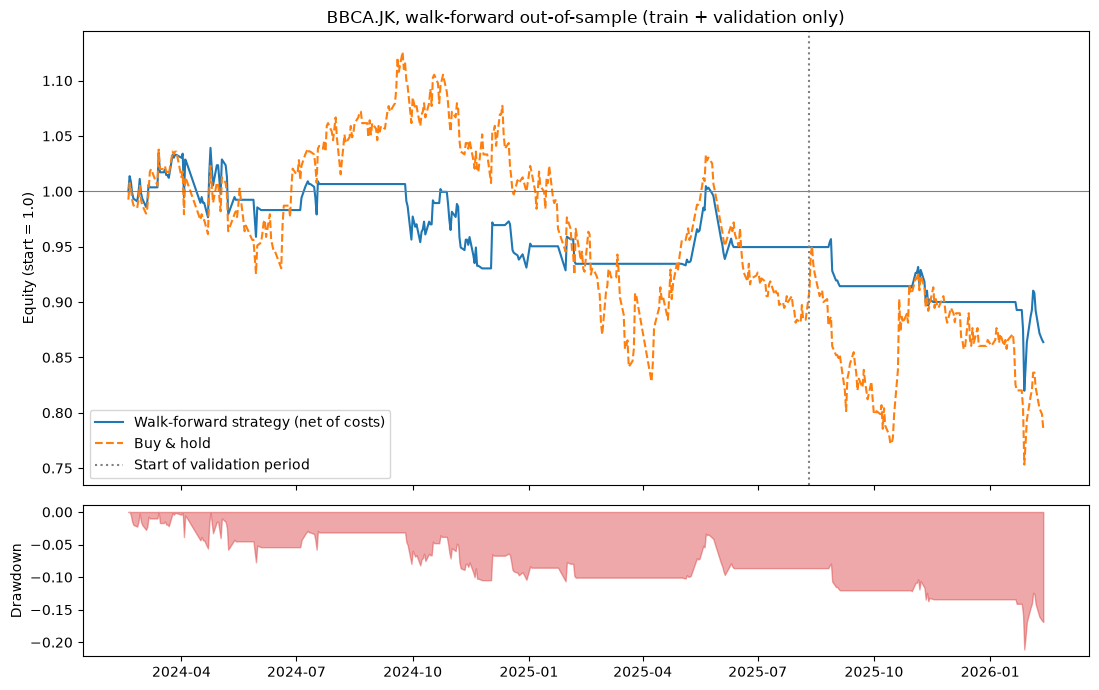

In [6]:
ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
(ROOT / "docs" / "results").mkdir(parents=True, exist_ok=True)
(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)
table[cols].round(4).to_csv(ROOT / "docs" / "results" / "day22_walk_forward.csv")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(daily_wf.index, daily_wf["equity"], label="Walk-forward strategy (net of costs)")
ax1.plot(daily_wf.index, daily_wf["benchmark_equity"], linestyle="--", label="Buy & hold")
ax1.axvline(split.val.index[0], color="grey", linestyle=":", label="Start of validation period")
ax1.axhline(1.0, color="grey", linewidth=0.8)
ax1.set_ylabel("Equity (start = 1.0)")
ax1.set_title("BBCA.JK, walk-forward out-of-sample (train + validation only)")
ax1.legend()

drawdown = daily_wf["equity"] / daily_wf["equity"].cummax() - 1
ax2.fill_between(daily_wf.index, drawdown, 0, alpha=0.4, color="tab:red")
ax2.set_ylabel("Drawdown")

plt.tight_layout()
plt.savefig(ROOT / "docs" / "figures" / "day22_walk_forward.png", dpi=150)
plt.show()

In [7]:
rows = {}
for label, kw in {
    "rolling 120": dict(train_size=120, rolling=True),
    "rolling 250": dict(train_size=250, rolling=True),
    "expanding 250": dict(train_size=250, rolling=False),
}.items():
    p = walk_forward_proba(dev, model, feature_cols, step=20, gap=1, **kw)
    r = returns.loc[p.index]
    rows[label] = describe(run_backtest(r, proba_to_signal(p)), r, p, dev.loc[p.index, "direction"])

pd.DataFrame(rows).T[["cum_return", "bench_cum_return", "bench_matched", "auc", "n_days"]].round(3)

,cum_return,bench_cum_return,bench_matched,auc,n_days
rolling 120,-0.095,-0.147,-0.047,0.504,601.0
rolling 250,-0.136,-0.215,-0.060,0.498,471.0
expanding 250,0.101,-0.215,-0.066,0.522,471.0


In [8]:
def wf_for(ticker: str) -> pd.Series:
    o = clean_ticker_data(raw[ticker])
    ds = build_dataset(o)
    sp = time_based_split(ds)
    cols_ = [c for c in ds.columns if c not in ("forward_return", "direction")]
    d = pd.concat([sp.train, sp.val])
    p = walk_forward_proba(d, model, cols_, **PARAMS)
    r = o["Close"].pct_change().loc[p.index]
    return describe(run_backtest(r, proba_to_signal(p)), r, p, d.loc[p.index, "direction"])

multi = pd.DataFrame({t: wf_for(t) for t in cfg.tickers}).T
multi[["cum_return", "bench_cum_return", "bench_matched", "max_drawdown", "exposure", "auc", "n_days"]].round(3)

,cum_return,bench_cum_return,bench_matched,max_drawdown,exposure,auc,n_days
BBCA.JK,-0.136,-0.215,-0.060,-0.211,0.316,0.498,471.0
BBRI.JK,-0.207,-0.274,-0.138,-0.353,0.544,0.501,471.0
TLKM.JK,0.004,-0.020,0.020,-0.377,0.499,0.510,471.0
ASII.JK,0.571,0.573,0.143,-0.097,0.257,0.557,471.0
UNVR.JK,0.163,-0.091,0.018,-0.225,0.285,0.498,471.0
